In [1]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

In [3]:
df .shape

(891, 12)

In [5]:
df .info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


In [6]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [7]:
# 1. Estadísticas descriptivas de las columnas numéricas
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
# 2. Estadísticas descriptivas de las columnas NO numéricas
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [9]:
# 1. Cuenta los nulos por columna con isnull().sum()
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


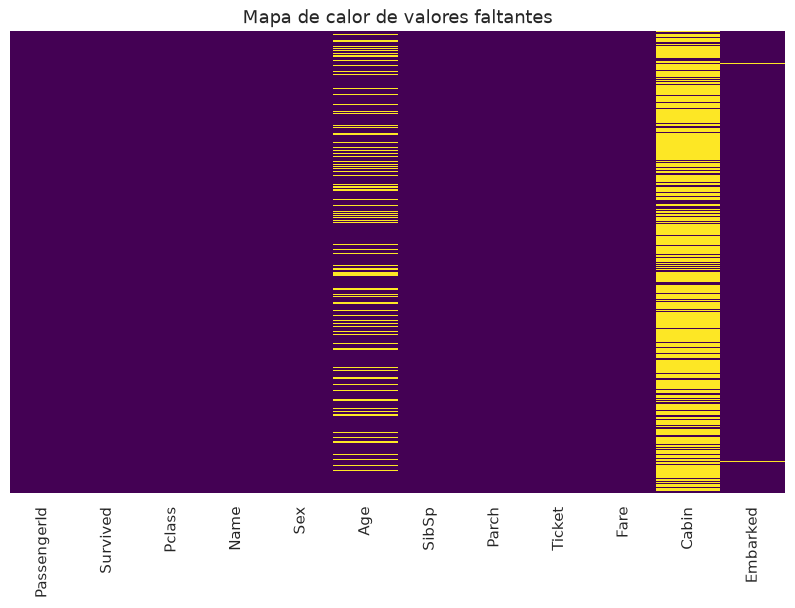

In [10]:
# 2. Dibuja el mapa de calor de df.isnull()
plt.figure(figsize=(10, 6)) # Opcional: hace el gráfico más grande
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
# 3. Añade un título y muestra el gráfico
plt.title('Mapa de calor de valores faltantes')
plt.show()

/tmp/ipykernel_67896/3155562742.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sex', palette='viridis')


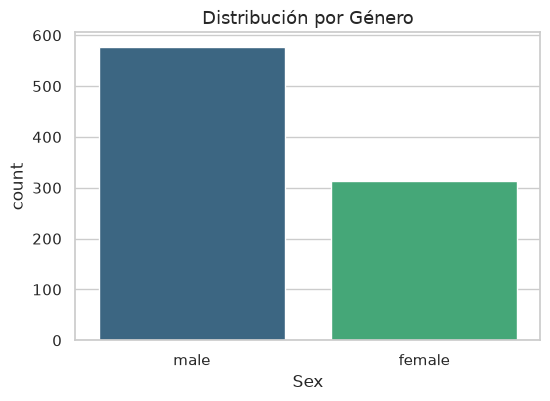

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', palette='viridis')
plt.title('Distribución por Género')
plt.show()

/tmp/ipykernel_67896/4127924827.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sex', palette='viridis')


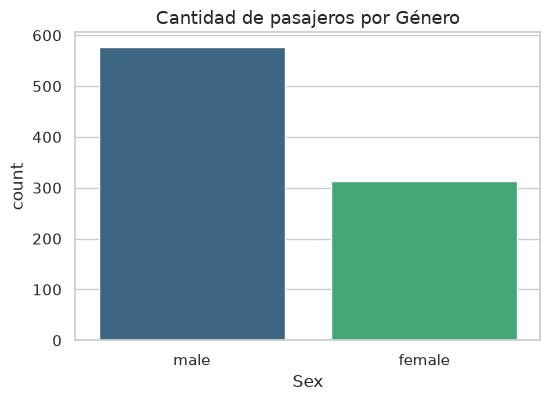

In [12]:
# 1. Gráfico de conteo de 'Sex'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', palette='viridis')
plt.title('Cantidad de pasajeros por Género')
plt.show()

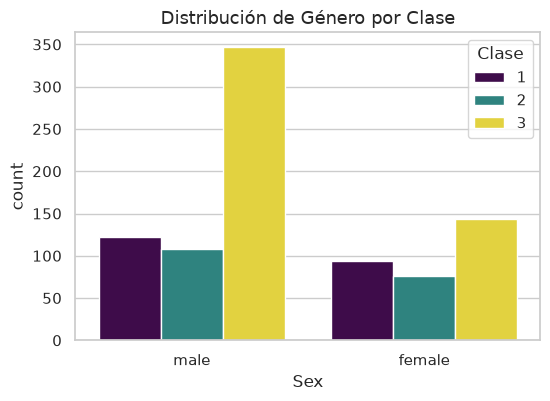

In [13]:
# 2. Gráfico de conteo de 'Sex' con hue='Pclass'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', hue='Pclass', palette='viridis')
plt.title('Distribución de Género por Clase')
plt.legend(title='Clase')
plt.show()

In [27]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.cwd()

while not (ROOT / "flows").exists():
    ROOT = ROOT.parent

print("Carpeta del proyecto:", ROOT)

Carpeta del proyecto: /home/luis_carlos_tez/proyectos/proyecto_ciencia_de_datos


In [28]:
BRONZE = ROOT / "data" / "bronze"

for archivo in sorted(BRONZE.iterdir()):
    print(archivo.name)

_ingestion_metadata.json
titanic_labeled.csv
titanic_unlabeled.csv


In [29]:
archivo = next(
    p for p in BRONZE.iterdir()
    if "titanic_labeled" in p.name.lower()
)

if archivo.suffix == ".parquet":
    df = pd.read_parquet(archivo)
elif archivo.suffix == ".csv":
    df = pd.read_csv(archivo)
else:
    raise ValueError(f"Formato no contemplado: {archivo.suffix}")

print("Datos cargados:", df.shape)
display(df.head())

Datos cargados: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [30]:
import importlib.util

ruta = ROOT / "flows" / "01_data_engineering.py"

spec = importlib.util.spec_from_file_location(
    "data_engineering", ruta
)

modulo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(modulo)

print("Función importada correctamente")

Función importada correctamente


In [31]:
df = modulo.add_person(df)

display(df[["Age", "Sex", "Person"]].head(10))

,Age,Sex,Person
0,22.0,male,male
1,38.0,female,female
2,26.0,female,female
3,35.0,female,female
4,35.0,male,male
5,NaN,male,male
6,54.0,male,male
7,2.0,male,child
8,27.0,female,female
9,14.0,female,child


In [32]:
df["Person"].value_counts()

Person
male      537
female    271
child      83
Name: count, dtype: int64

In [33]:
df.groupby("Person")["Survived"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
Person,,,
child,83,49.0,0.590361
female,271,205.0,0.756458
male,537,88.0,0.163873


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

PARTE 2 // PASO 10

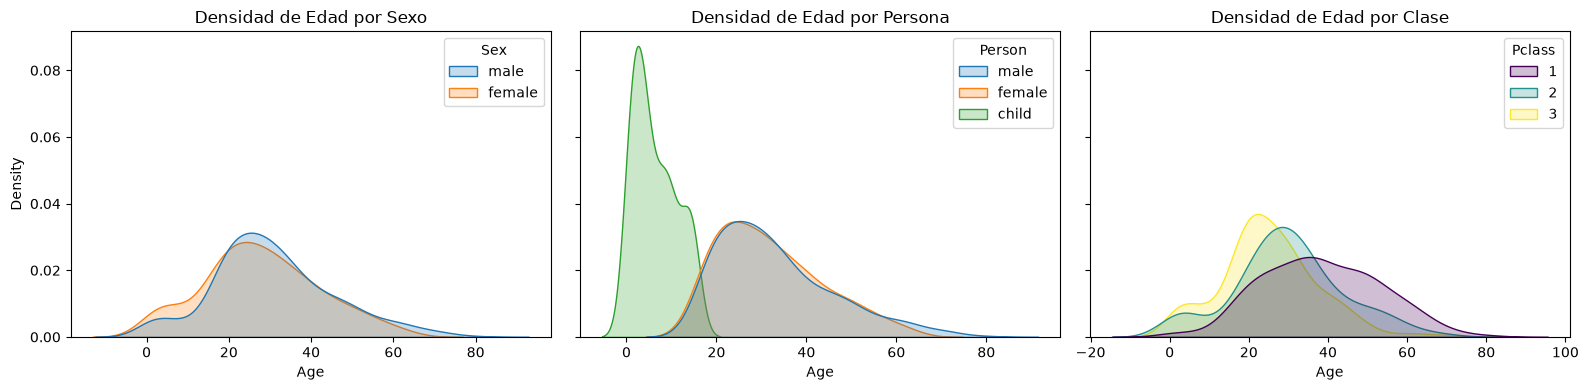

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from flows.common.paths import BRONZE, BRONZE_LABELED_NAME

# 1. Nos aseguramos de tener los datos cargados desde el archivo original
# (Esto evita el error de que 'df' no exista)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

# 2. Replicamos exactamente la lógica de tu función add_person
df_person = df.copy()
df_person['Person'] = np.where(df_person['Age'] < 16, 'child', df_person['Sex'])

# 3. Creamos la figura de 1 fila x 3 columnas para el Paso 10
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# Gráfico 1: Por Sexo
sns.kdeplot(data=df_person, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Densidad de Edad por Sexo')

# Gráfico 2: Por Persona (usando la variable que acabamos de crear)
sns.kdeplot(data=df_person, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Densidad de Edad por Persona')

# Gráfico 3: Por Clase
sns.kdeplot(data=df_person, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('Densidad de Edad por Clase')

# 4. Ajustamos y mostramos
plt.tight_layout()
plt.show()

PARTE 3 PASO 11

In [6]:
# 1. Aplicamos la lógica localmente para que funcione ya mismo
df_cabin = df_person.copy()
df_cabin['TCabin'] = df_cabin['Cabin'].str[0].fillna('X')
df_cabin['HasCabin'] = df_cabin['Cabin'].notna().astype(int)

# 2. Mostramos el conteo de pasajeros por tipo de cabina (Paso 11 del cuaderno)
print("Conteo por tipo de cubierta (TCabin):")
print(df_cabin['TCabin'].value_counts())

# 3. (Opcional) Ver cuántos tienen y no tienen cabina
print("\n¿Tienen cabina registrada? (1=Sí, 0=No):")
print(df_cabin['HasCabin'].value_counts())

Conteo por tipo de cubierta (TCabin):
TCabin
X    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64

¿Tienen cabina registrada? (1=Sí, 0=No):
HasCabin
0    687
1    204
Name: count, dtype: int64


PARTE 3 / PASO 12

/tmp/ipykernel_113167/2393764245.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=cubierta, order=sorted(cubierta.unique()), palette='viridis')


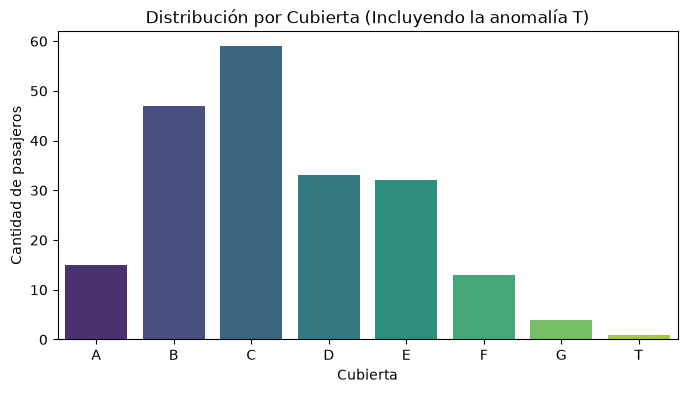

/tmp/ipykernel_113167/2393764245.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=cubierta_filtrada, order=sorted(cubierta_filtrada.unique()), palette='viridis')


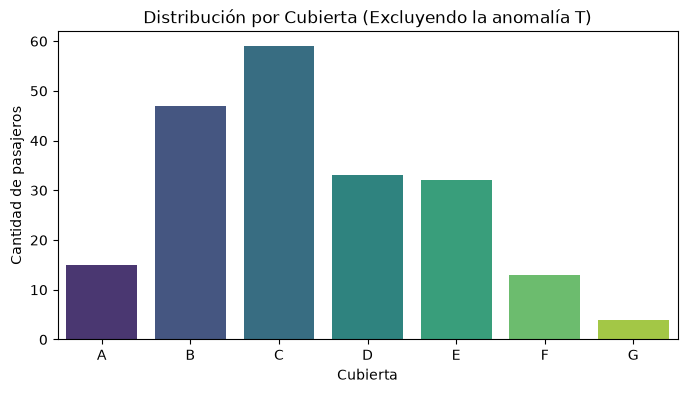

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtramos SOLO las cabinas conocidas (quitamos las 'X')
cubierta = df_cabin.loc[df_cabin['TCabin'] != 'X', 'TCabin']

# --- GRÁFICO 1: Con la anomalía (la 'T') ---
plt.figure(figsize=(8, 4))
sns.countplot(x=cubierta, order=sorted(cubierta.unique()), palette='viridis')
plt.title('Distribución por Cubierta (Incluyendo la anomalía T)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad de pasajeros')
plt.show()

# 2. Excluimos la cubierta 'T' SOLO para el gráfico
cubierta_filtrada = cubierta[cubierta != 'T']

# --- GRÁFICO 2: Sin la anomalía ---
plt.figure(figsize=(8, 4))
sns.countplot(x=cubierta_filtrada, order=sorted(cubierta_filtrada.unique()), palette='viridis')
plt.title('Distribución por Cubierta (Excluyendo la anomalía T)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad de pasajeros')
plt.show()

PARTE 3 / PASO 13

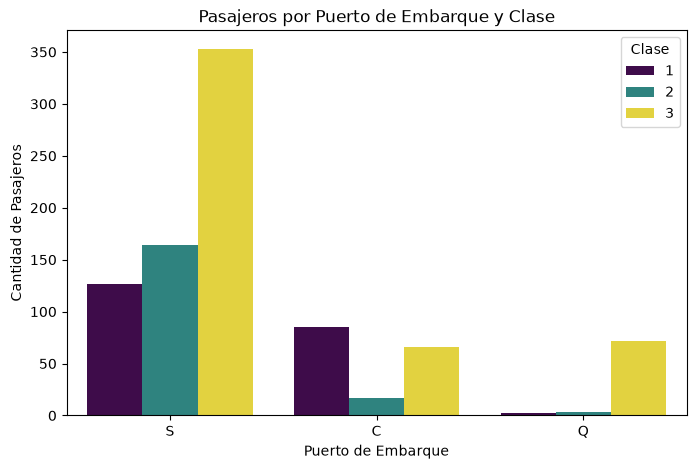

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Gráfico de conteo de 'Embarked' con hue='Pclass'
plt.figure(figsize=(8, 5))
sns.countplot(data=df_cabin, x='Embarked', hue='Pclass', palette='viridis')
plt.title('Pasajeros por Puerto de Embarque y Clase')
plt.xlabel('Puerto de Embarque')
plt.ylabel('Cantidad de Pasajeros')
plt.legend(title='Clase')
plt.show()

# 2. Tabla cruzada normalizada POR FILAS (normalize='index')
# Esto te dirá qué porcentaje de cada puerto corresponde a cada clase
tabla_embarque_clase = pd.crosstab(df_cabin['Embarked'], df_cabin['Pclass'], normalize='index')
tabla_embarque_clase.round(2)

PARTE 3 / PASO 14 Y 15

Proporción de pasajeros (0 a 1):
Alone
Alone          0.6
with Family    0.4
Name: proportion, dtype: float64


/tmp/ipykernel_113167/1651887302.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_family, x='Alone', palette='Set2')


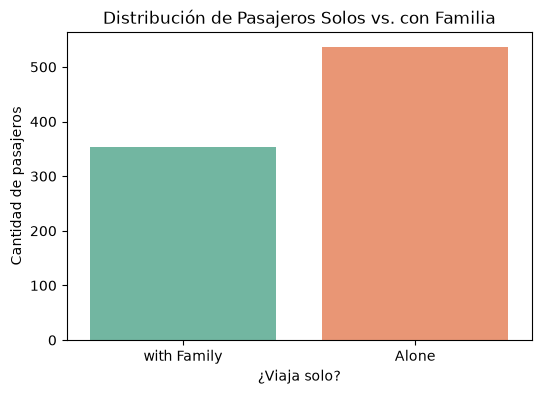

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- PASO 14: Calcular proporciones ---
# 1. Aplicamos la lógica al dataframe que venimos trabajando (df_cabin)
df_family = df_cabin.copy()
df_family['Familia'] = df_family['SibSp'] + df_family['Parch']
df_family['Alone'] = np.where(df_family['Familia'] > 0, 'with Family', 'Alone')

# 2. Calculamos la proporción (normalize=True nos da porcentajes en vez de conteos)
print("Proporción de pasajeros (0 a 1):")
proporciones = df_family['Alone'].value_counts(normalize=True).round(2)
print(proporciones)


# --- PASO 15: Visualizar la distribución ---
plt.figure(figsize=(6, 4))
sns.countplot(data=df_family, x='Alone', palette='Set2')
plt.title('Distribución de Pasajeros Solos vs. con Familia')
plt.xlabel('¿Viaja solo?')
plt.ylabel('Cantidad de pasajeros')
plt.show()

PARTE 4 / PASO 16

/tmp/ipykernel_113167/4011584133.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_surv, x='Survivor', palette='Set1')


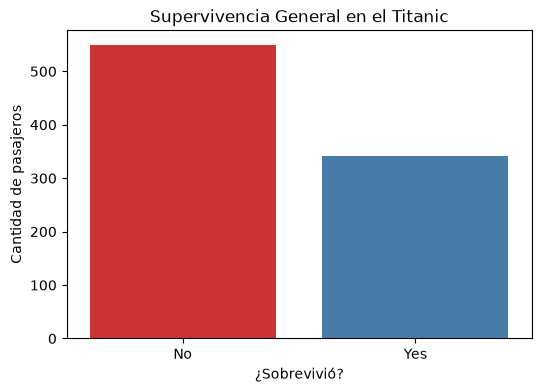

La tasa general de supervivencia es: 38.38%


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Creamos la columna 'Survivor' con texto
df_surv = df_family.copy()
df_surv['Survivor'] = df_surv['Survived'].map({0: 'No', 1: 'Yes'})

# 2. Gráfico de conteo de 'Survivor'
plt.figure(figsize=(6, 4))
sns.countplot(data=df_surv, x='Survivor', palette='Set1')
plt.title('Supervivencia General en el Titanic')
plt.xlabel('¿Sobrevivió?')
plt.ylabel('Cantidad de pasajeros')
plt.show()

# 3. Calcular la tasa general de supervivencia (la media de una variable 0/1)
tasa_supervivencia = df_surv['Survived'].mean()

# 4. Imprimir el resultado en porcentaje para verificarlo
print(f"La tasa general de supervivencia es: {tasa_supervivencia * 100:.2f}%")

PARTE 4 / PASO 17

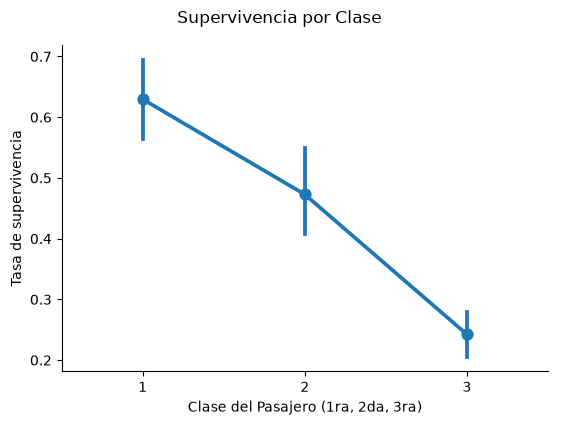

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Creamos el gráfico de puntos (Point Plot)
# Usamos df_surv que es el que tiene la columna 'Survived' lista
g = sns.catplot(data=df_surv, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)

# Añadimos título y etiquetas (usando g.set para que funcione bien con catplot)
g.set_axis_labels("Clase del Pasajero (1ra, 2da, 3ra)", "Tasa de supervivencia")
g.fig.suptitle('Supervivencia por Clase', y=1.05)

plt.show()

PARTE 4 / PASO 18

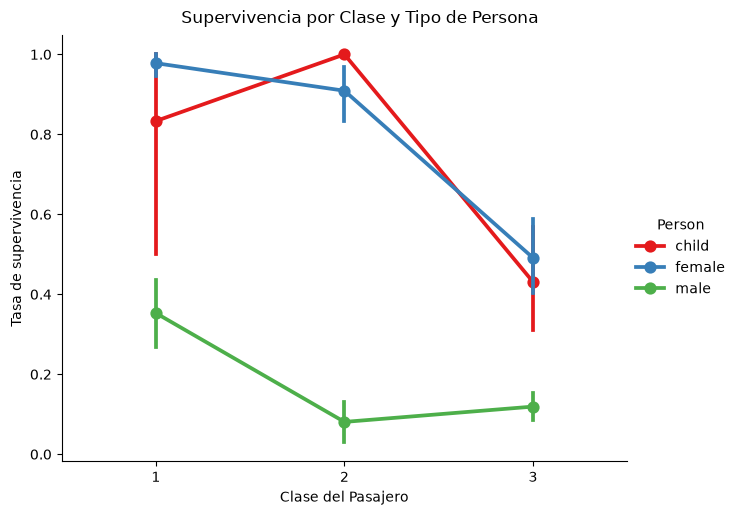

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico de puntos repitiendo el anterior, pero añadiendo Person
g = sns.catplot(
    data=df_surv, 
    x='Pclass', 
    y='Survived', 
    hue='Person', 
    hue_order=['child', 'female', 'male'], # Forzamos este orden
    kind='point', 
    height=5, 
    aspect=1.3,
    palette='Set1'
)

g.set_axis_labels("Clase del Pasajero", "Tasa de supervivencia")
g.fig.suptitle('Supervivencia por Clase y Tipo de Persona', y=1.02)
plt.show()

PARTE 4 / PASO 19

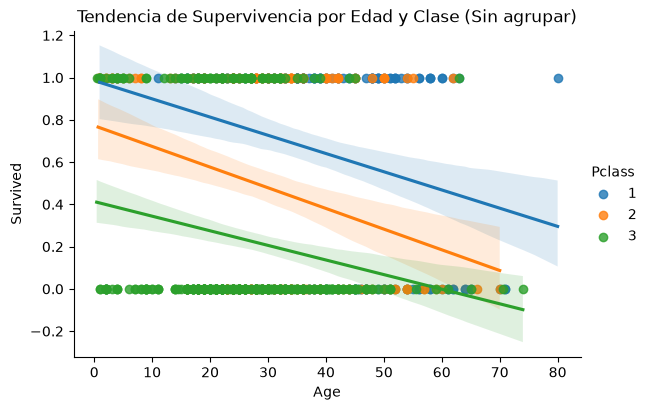

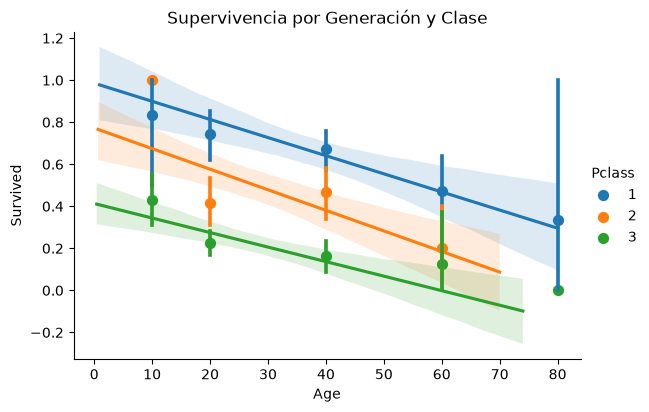

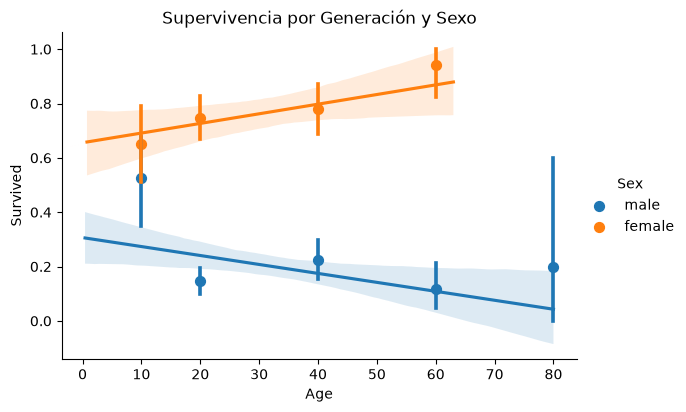

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1 y 2: lmplot básico con hue='Pclass'
sns.lmplot(data=df_surv, x='Age', y='Survived', hue='Pclass', height=4, aspect=1.5)
plt.title('Tendencia de Supervivencia por Edad y Clase (Sin agrupar)')
plt.show()

# 3: Usando generaciones (x_bins) con hue='Pclass'
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df_surv, x='Age', y='Survived', hue='Pclass', x_bins=generaciones, height=4, aspect=1.5)
plt.title('Supervivencia por Generación y Clase')
plt.show()

# 4: Repetir el punto 3 con hue='Sex'
sns.lmplot(data=df_surv, x='Age', y='Survived', hue='Sex', x_bins=generaciones, height=4, aspect=1.5)
plt.title('Supervivencia por Generación y Sexo')
plt.show()

PARTE 4 / PASO 20

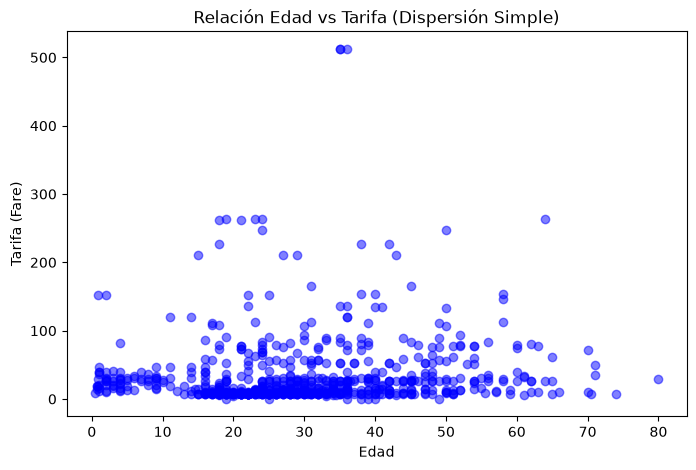

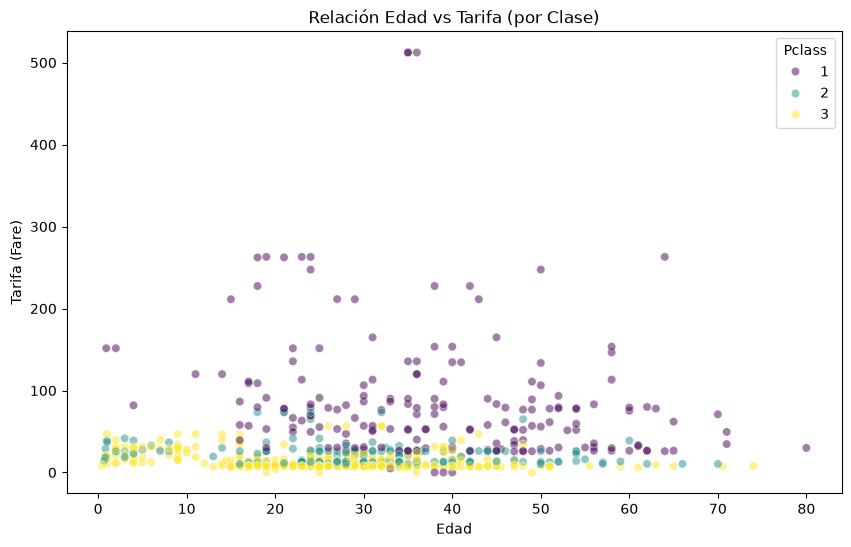

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dispersión simple
plt.figure(figsize=(8, 5))
plt.scatter(df_surv['Age'], df_surv['Fare'], alpha=0.5, color='blue')
plt.title('Relación Edad vs Tarifa (Dispersión Simple)')
plt.xlabel('Edad')
plt.ylabel('Tarifa (Fare)')
plt.show()

# 2. Desafío: Dispersión con hue='Pclass'
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_surv, 
    x='Age', 
    y='Fare', 
    hue='Pclass', 
    alpha=0.5, 
    palette='viridis'
)
plt.title('Relación Edad vs Tarifa (por Clase)')
plt.xlabel('Edad')
plt.ylabel('Tarifa (Fare)')
plt.show()

PARTE 5 // PASO 21 

In [17]:
import pandas as pd

# 1. ¿Cuántos valores faltan en 'Embarked'?
nulos_embarked = df_surv['Embarked'].isnull().sum()
print(f"Valores faltantes en Embarked: {nulos_embarked}")

# 2. Calculamos la categoría más frecuente (la moda)
moda_embarked = df_surv['Embarked'].mode()[0]
print(f"La categoría más frecuente es: '{moda_embarked}'")

# 3. Rellenamos los faltantes con esa moda
# (Usamos .copy() para no modificar df_surv original y crear un df final)
df_clean = df_surv.copy()
df_clean['Embarked'] = df_clean['Embarked'].fillna(moda_embarked)

# Verificamos que ya no queden nulos
print(f"Nulos después de imputar: {df_clean['Embarked'].isnull().sum()}")

# 4. Creamos NEmbarked (S -> 0, C -> 1, Q -> 2)
df_clean['NEmbarked'] = df_clean['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# Mostramos cómo quedó la tabla
print("\nPrimeras filas mostrando Embarked y NEmbarked:")
display(df_clean[['Embarked', 'NEmbarked']].head())

Valores faltantes en Embarked: 2
La categoría más frecuente es: 'S'
Nulos después de imputar: 0

Primeras filas mostrando Embarked y NEmbarked:


,Embarked,NEmbarked
0,S,0
1,C,1
2,S,0
3,S,0
4,S,0


PARTE 5 / PASO 22 Y 22.1

In [18]:
import pandas as pd
import numpy as np

# 1. Preparamos las columnas de control
df_imp = df_clean.copy()
df_imp['AgeOriginal'] = df_imp['Age']
df_imp['AgeImputada'] = df_imp['Age'].isna()

# 2. Calculamos el promedio por Sexo
promedios_sexo = df_imp.groupby('Sex')['Age'].mean()
print("Promedios de edad por sexo:\n", promedios_sexo)

# 3. Rellenamos los nulos
df_imp['Age'] = df_imp['Age'].fillna(df_imp['Sex'].map(promedios_sexo))

# 4. Verificamos que ya no queden nulos
print(f"\nNulos en Age después de imputar: {df_imp['Age'].isnull().sum()}")

Promedios de edad por sexo:
 Sex
female    27.915709
male      30.726645
Name: Age, dtype: float64

Nulos en Age después de imputar: 0


In [19]:
# Desviación estándar ANTES (usando AgeOriginal que tiene los nulos)
std_antes = df_imp['AgeOriginal'].std()

# Desviación estándar DESPUÉS (usando Age ya imputada)
std_despues = df_imp['Age'].std()

print(f"Desviación estándar ANTES: {std_antes:.4f}")
print(f"Desviación estándar DESPUÉS: {std_despues:.4f}")

Desviación estándar ANTES: 14.5265
Desviación estándar DESPUÉS: 13.0149


PARTE 5 / PASO 23 Y 24 

In [20]:
import pandas as pd

# Creamos un nuevo dataframe para las codificaciones
df_encoded = df_imp.copy()

# 1. Codificar Sex (Paso 23)
df_encoded['NSex'] = df_encoded['Sex'].map({'female': 0, 'male': 1})

# 2. Codificar Cabin (Paso 24)
# Definimos la lista de cubiertas fija (tal como está en tu archivo .py)
DECKS = list("ABCDEFGTX") 
mapa_cabin = {letra: i for i, letra in enumerate(DECKS)}
df_encoded['NCabin'] = df_encoded['TCabin'].map(mapa_cabin)

# 3. Mostramos los resultados para verificar
print("Mapeo de Sexo (NSex):")
print(df_encoded[['Sex', 'NSex']].drop_duplicates())

print("\nMapeo de Cabina (NCabin) - Primeras 10 filas:")
display(df_encoded[['TCabin', 'NCabin']].head(10))

print("\nRango de valores de NCabin:")
print(f"Mínimo: {df_encoded['NCabin'].min()}, Máximo: {df_encoded['NCabin'].max()}")

Mapeo de Sexo (NSex):
      Sex  NSex
0    male     1
1  female     0

Mapeo de Cabina (NCabin) - Primeras 10 filas:


,TCabin,NCabin
0,X,8
1,C,2
2,X,8
3,C,2
4,X,8
5,X,8
6,E,4
7,X,8
8,X,8
9,X,8



Rango de valores de NCabin:
Mínimo: 0, Máximo: 8


PARTE 5 / PASO 25

In [21]:
import pandas as pd

# 1. Creamos la columna TTitulo usando la expresión regular
df_titles = df_encoded.copy()
df_titles['TTitulo'] = df_titles['Name'].str.extract(r',\s*([^\.]+)\.', expand=False).str.strip()

# 2. Analizamos la frecuencia de cada título
print("Frecuencia de Títulos:")
print(df_titles['TTitulo'].value_counts())

# 3. Tabla cruzada de Título vs Género
print("\nTabla cruzada: Título vs Género")
tabla_titulos = pd.crosstab(df_titles['TTitulo'], df_titles['Sex'])
display(tabla_titulos)

Frecuencia de Títulos:
TTitulo
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Tabla cruzada: Título vs Género


Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


PARTE 5 / PASO 26

In [22]:
# Definimos las constantes (las mismas de tu archivo .py)
TITLE_MAP = {
    "Master": "Mr", "the Countess": "Mrs", "Dona": "Mrs", "Mme": "Mrs",
    "Lady": "Miss", "Mlle": "Miss", "Ms": "Miss",
}
MAIN_TITLES = ["Mr", "Mrs", "Miss"]

# 1. Aplicamos la consolidación
df_consolidated = df_titles.copy()

# Reemplazamos los títulos del diccionario
df_consolidated['TTitulo'] = df_consolidated['TTitulo'].replace(TITLE_MAP)

# Convertimos lo que no sea Mr, Mrs o Miss en 'Otro'
df_consolidated['TTitulo'] = df_consolidated['TTitulo'].where(
    df_consolidated['TTitulo'].isin(MAIN_TITLES), 'Otro'
)

# 2. Revisamos los conteos finales
print("Conteo final de Títulos consolidados:")
print(df_consolidated['TTitulo'].value_counts())

# 3. Creamos la variable numérica NTitulo
df_consolidated['NTitulo'] = df_consolidated['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

Conteo final de Títulos consolidados:
TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64


PARTE 6 / PASO 27

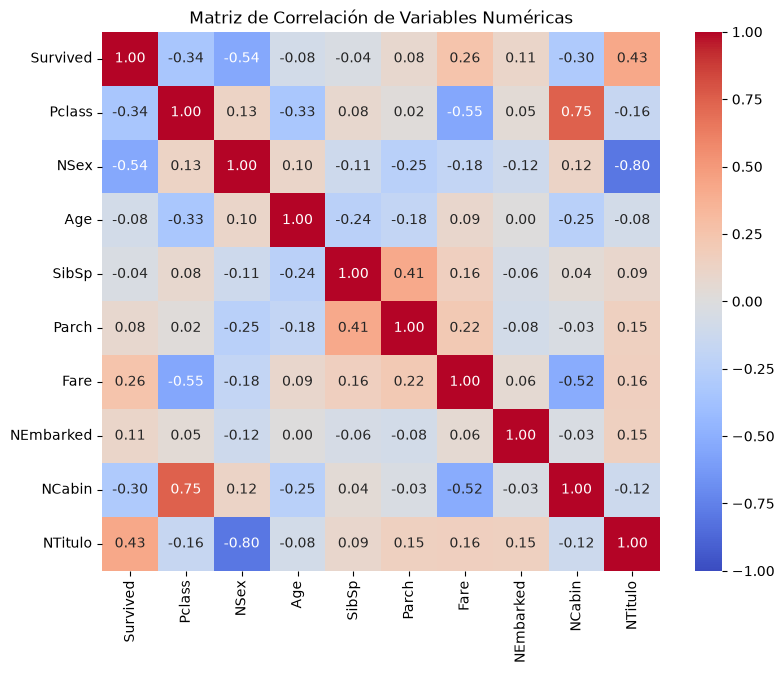

Correlación de cada variable con la Supervivencia (Survived):
Survived     1.000000
NTitulo      0.428661
Fare         0.257307
NEmbarked    0.106811
Parch        0.081629
SibSp       -0.035322
Age         -0.080453
NCabin      -0.301116
Pclass      -0.338481
NSex        -0.543351
Name: Survived, dtype: float64


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Elegimos las variables numéricas relevantes
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

# 2. Calculamos la matriz de correlación
corr = df_consolidated[cols].corr()

# 3. Dibujamos el heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

# 4. Imprimimos las correlaciones con 'Survived' ordenadas
print("Correlación de cada variable con la Supervivencia (Survived):")
print(corr['Survived'].sort_values(ascending=False))

PARTE 6 / PASO 28 

In [24]:
import pandas as pd

# 1. Tabla de edades según supervivencia (describe)
age_by_survival = df_consolidated.groupby('Survived')['Age'].describe().reset_index()
print("--- Estadísticas de Edad por Supervivencia ---")
display(age_by_survival)

# 2. Supervivencia por Sexo
survival_by_sex = df_consolidated.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count']).reset_index()
print("\n--- Supervivencia por Sexo ---")
display(survival_by_sex)

# 3. Supervivencia por Clase
survival_by_pclass = df_consolidated.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count']).reset_index()
print("\n--- Supervivencia por Clase ---")
display(survival_by_pclass)

# 4. Supervivencia por Alone
survival_by_alone = df_consolidated.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count']).reset_index()
print("\n--- Supervivencia por Alone ---")
display(survival_by_alone)

--- Estadísticas de Edad por Supervivencia ---


,Survived,count,mean,std,min,25%,50%,75%,max
0,0.0,549.0,30.562012,12.460355,1.00,23.0,30.726645,35.0,74.0
1,1.0,342.0,28.410122,13.774087,0.42,21.0,27.915709,35.0,80.0



--- Supervivencia por Sexo ---


,Sex,mean,sum,count
0,female,0.742038,233.0,314
1,male,0.188908,109.0,577



--- Supervivencia por Clase ---


,Pclass,mean,sum,count
0,1,0.629630,136.0,216
1,2,0.472826,87.0,184
2,3,0.242363,119.0,491



--- Supervivencia por Alone ---


,Alone,mean,sum,count
0,Alone,0.303538,163.0,537
1,with Family,0.505650,179.0,354


PARTE 6 / PASO 29

In [30]:
import pandas as pd
from scipy import stats

# 1. Creamos la tabla de contingencia
tabla_sex = pd.crosstab(df_consolidated['Sex'], df_consolidated['Survived'])
print("Tabla de Contingencia (Observados):")
display(tabla_sex)

# 2. Aplicamos la prueba
chi2, p_value, dof, expected = stats.chi2_contingency(tabla_sex)

# 3. Imprimimos los resultados
print(f"\nResultados de la prueba Chi-cuadrado:")
print(f"Estadístico Chi2: {chi2:.4f}")
print(f"Grados de libertad (dof): {dof}")
print(f"P-valor: {p_value:.4e}") # Lo imprimimos en notación científica porque será un número minúsculo

Tabla de Contingencia (Observados):


Survived,0.0,1.0
Sex,,
female,81,233
male,468,109



Resultados de la prueba Chi-cuadrado:
Estadístico Chi2: 260.7170
Grados de libertad (dof): 1
P-valor: 1.1974e-58


PARTE 7 / PASOS 30 - 31

/tmp/ipykernel_113167/2035175605.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_consolidated, x='Sex', y='AgeOriginal', ax=axes[0,0], palette='Set2')
/tmp/ipykernel_113167/2035175605.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_consolidated, x='Pclass', y='AgeOriginal', ax=axes[0,1], palette='Set2')
/tmp/ipykernel_113167/2035175605.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_consolidated, x='Embarked', y='AgeOriginal', ax=axes[1,0], palette='Set2')
/tmp/ipykernel_113167/2035175605.py:23: FutureWa

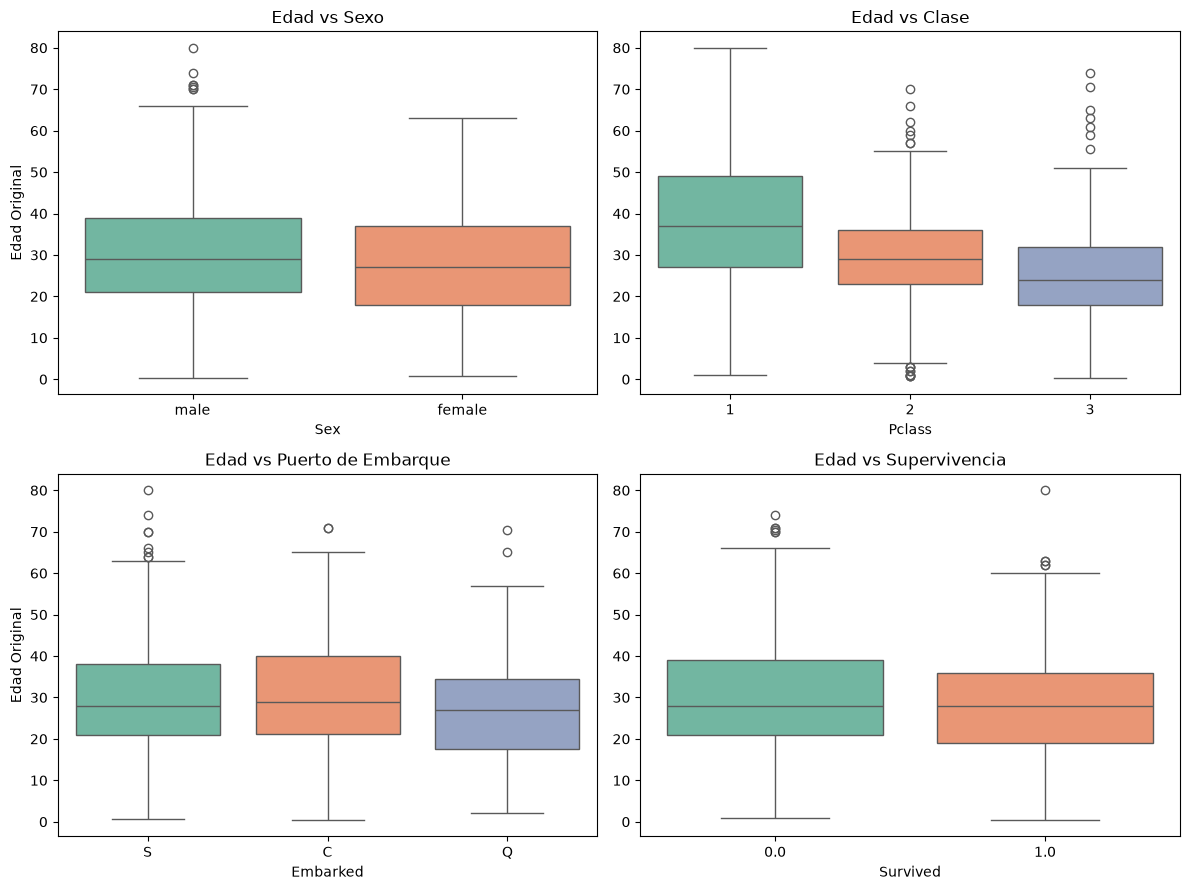

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Creamos la cuadrícula de 2x2
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 2. Gráfico 1: Edad por Sexo (arriba a la izquierda)
sns.boxplot(data=df_consolidated, x='Sex', y='AgeOriginal', ax=axes[0,0], palette='Set2')
axes[0,0].set_title('Edad vs Sexo')
axes[0,0].set_ylabel('Edad Original')

# 3. Gráfico 2: Edad por Clase (arriba a la derecha)
sns.boxplot(data=df_consolidated, x='Pclass', y='AgeOriginal', ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Edad vs Clase')
axes[0,1].set_ylabel('') # Ocultamos el Y para que se vea más limpio

# 4. Gráfico 3: Edad por Puerto de Embarque (abajo a la izquierda)
sns.boxplot(data=df_consolidated, x='Embarked', y='AgeOriginal', ax=axes[1,0], palette='Set2')
axes[1,0].set_title('Edad vs Puerto de Embarque')
axes[1,0].set_ylabel('Edad Original')

# 5. Gráfico 4: Edad por Supervivencia (abajo a la derecha)
sns.boxplot(data=df_consolidated, x='Survived', y='AgeOriginal', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Edad vs Supervivencia')
axes[1,1].set_ylabel('')

# Ajustamos y mostramos
plt.tight_layout()
plt.show()

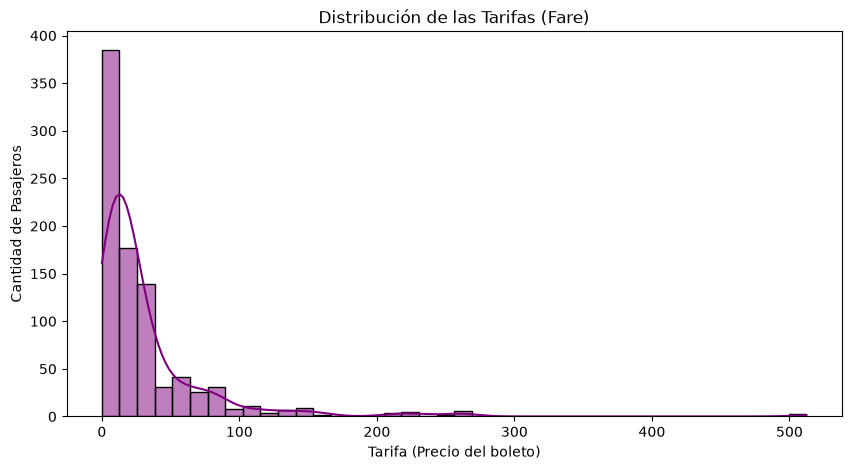

Media de la tarifa:   $32.20
Mediana de la tarifa: $14.45
Asimetría (Skew):     4.79


In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Histograma con KDE
plt.figure(figsize=(10, 5))
sns.histplot(df_consolidated['Fare'], kde=True, bins=40, color='purple')
plt.title('Distribución de las Tarifas (Fare)')
plt.xlabel('Tarifa (Precio del boleto)')
plt.ylabel('Cantidad de Pasajeros')
plt.show()

# 2. Cálculos estadísticos
media = df_consolidated['Fare'].mean()
mediana = df_consolidated['Fare'].median()
asimetria = df_consolidated['Fare'].skew()

print(f"Media de la tarifa:   ${media:.2f}")
print(f"Mediana de la tarifa: ${mediana:.2f}")
print(f"Asimetría (Skew):     {asimetria:.2f}")

PARTE 8 / PASOS 32 33

In [33]:
import pandas as pd

# 1. Aplicamos la limpieza final
df_final = df_consolidated.copy()
columnas_eliminar = ['Name', 'Sex', 'Embarked', 'Cabin']
df_final = df_final.drop(columns=columnas_eliminar)

# 2. Revisamos que las columnas de texto hayan desaparecido
print("Columnas restantes en el dataset final:")
print(df_final.columns.tolist())

print("\nPrimeras 5 filas del dataset final (todo numérico):")
display(df_final.head())

Columnas restantes en el dataset final:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Person', 'TCabin', 'HasCabin', 'Familia', 'Alone', 'Survivor', 'NEmbarked', 'AgeOriginal', 'AgeImputada', 'NSex', 'NCabin', 'TTitulo', 'NTitulo']

Primeras 5 filas del dataset final (todo numérico):


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Ticket,Fare,Person,TCabin,...,Familia,Alone,Survivor,NEmbarked,AgeOriginal,AgeImputada,NSex,NCabin,TTitulo,NTitulo
0,1,0.0,3,22.0,1,0,A/5 21171,7.2500,male,X,...,1,with Family,No,0,22.0,False,1,8,Mr,0
1,2,1.0,1,38.0,1,0,PC 17599,71.2833,female,C,...,1,with Family,Yes,1,38.0,False,0,2,Mrs,1
2,3,1.0,3,26.0,0,0,STON/O2. 3101282,7.9250,female,X,...,0,Alone,Yes,0,26.0,False,0,8,Miss,2
3,4,1.0,1,35.0,1,0,113803,53.1000,female,C,...,1,with Family,Yes,0,35.0,False,0,2,Mrs,1
4,5,0.0,3,35.0,0,0,373450,8.0500,male,X,...,0,Alone,No,0,35.0,False,1,8,Mr,0


PARTE 8 // PASO 32 - 33 // 

pytest tests/test_01_data_engineering.py -q

11 passed in 0.35s

make silver

891 filas, 25 columnas

data/silver/

 titanic_final.parquet   titanic_silver.parquet



PARTE 9 / PASOS 34 - 38 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargamos el dataset completo (Silver) que generamos con el pipeline
df_silver = pd.read_parquet('../data/silver/titanic_silver.parquet')

print("--- PASO 34: Interacciones Clase x Género ---")
# Usamos pivot_table para cruzar variables
# index=filas (Pclass), columns=columnas (Sex), values=lo que calculamos (Survived), aggfunc=como lo calculamos (mean=tasa)
tabla_clase_sexo = df_silver.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')
display(tabla_clase_sexo.round(3)) # Redondeamos a 3 decimales

--- PASO 34: Interacciones Clase x Género ---


Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.5,0.135


In [3]:
print("\n--- PASO 35: Puerto de embarque y supervivencia ---")
# 1. Tasa y número de pasajeros por puerto
survival_by_embarked = df_silver.groupby('Embarked')['Survived'].agg(['mean', 'count'])
display(survival_by_embarked.round(3))

# 2. Estratificando por clase (Pivot Table)
# index='Embarked' (filas), columns='Pclass' (columnas), values='Survived' (tasa)
tabla_embarked_clase = df_silver.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean')
display(tabla_embarked_clase.round(3))


--- PASO 35: Puerto de embarque y supervivencia ---


,mean,count
Embarked,,
C,0.554,168
Q,0.39,77
S,0.339,646


Pclass,1,2,3
Embarked,,,
C,0.694,0.529,0.379
Q,0.5,0.667,0.375
S,0.589,0.463,0.19


PASO 36

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Aseguramos que tenemos el df_silver cargado
df_silver = pd.read_parquet('../data/silver/titanic_silver.parquet')

# --- PASO 36: Tarifa y supervivencia dentro de cada clase ---
# 1. Calculamos los cuartiles de la tarifa DENTRO de cada clase
df_silver['FareQ'] = df_silver.groupby('Pclass')['Fare'].transform(
    lambda s: pd.qcut(s, 4, labels=False, duplicates='drop')
)
# 2. Pivot table
tabla_tarifa_clase = df_silver.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean')
print("--- Paso 36: Tasa de supervivencia por Cuartil de Tarifa dentro de cada Clase ---")
display(tabla_tarifa_clase.round(3))

--- Paso 36: Tasa de supervivencia por Cuartil de Tarifa dentro de cada Clase ---


Pclass,1,2,3
FareQ,,,
0,0.463,0.345,0.227
1,0.574,0.5,0.2
2,0.745,0.585,0.276
3,0.736,0.59,0.283



--- Paso 37: Supervivencia por Tamaño de Familia ---


,Familia,mean,count
0,0,0.303538,537
1,1,0.552795,161
2,2,0.578431,102
3,3,0.724138,29
4,4,0.2,15
5,5,0.136364,22
6,6,0.333333,12
7,7,0.0,6
8,10,0.0,7


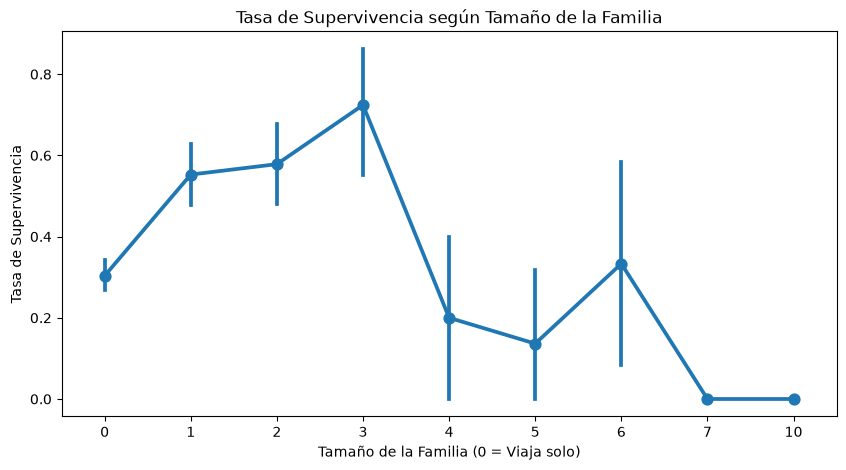

In [5]:
# --- PASO 37: Tamaño de la familia ---
survival_by_family = df_silver.groupby('Familia')['Survived'].agg(['mean', 'count']).reset_index()
print("\n--- Paso 37: Supervivencia por Tamaño de Familia ---")
display(survival_by_family)

# Gráfico de puntos
plt.figure(figsize=(10, 5))
sns.pointplot(data=df_silver, x='Familia', y='Survived', errorbar=('ci', 95))
plt.title('Tasa de Supervivencia según Tamaño de la Familia')
plt.xlabel('Tamaño de la Familia (0 = Viaja solo)')
plt.ylabel('Tasa de Supervivencia')
plt.show()

In [6]:
# --- PASO 38: Pasajeros atípicos (Outliers con IQR) ---
def outlier_mask_iqr(s):
    """Devuelve una máscara booleana para valores atípicos usando IQR."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < (q1 - 1.5 * iqr)) | (s > (q3 + 1.5 * iqr))

# Creamos la máscara para 'Fare'
mask_fare = outlier_mask_iqr(df_silver['Fare'])

# ¿Cuántos outliers hay en Tarifa, Edad y Familia?
print("\n--- Paso 38: Resumen de Atípicos (IQR) ---")
print(f"Outliers en Fare: {mask_fare.sum()} pasajeros")
print(f"Outliers en Age: {outlier_mask_iqr(df_silver['Age']).sum()} pasajeros")
print(f"Outliers en Familia: {outlier_mask_iqr(df_silver['Familia']).sum()} pasajeros")

# Supervivencia de los atípicos de Fare frente al resto
tasa_outliers = df_silver[mask_fare]['Survived'].mean()
tasa_resto = df_silver[~mask_fare]['Survived'].mean()
print(f"Supervivencia de atípicos ricos en Fare: {tasa_outliers:.2%}")
print(f"Supervivencia del resto: {tasa_resto:.2%}")

# Mostrar los pasajeros con la tarifa más alta
print("\nTop 5 pasajeros con las tarifas más altas:")
display(df_silver.nlargest(5, 'Fare')[['Name', 'Fare', 'Pclass', 'Survived']])


--- Paso 38: Resumen de Atípicos (IQR) ---
Outliers en Fare: 116 pasajeros
Outliers en Age: 66 pasajeros
Outliers en Familia: 91 pasajeros
Supervivencia de atípicos ricos en Fare: 68.10%
Supervivencia del resto: 33.94%

Top 5 pasajeros con las tarifas más altas:


,Name,Fare,Pclass,Survived
258,"Ward, Miss. Anna",512.3292,1,1
679,"Cardeza, Mr. Thomas Drake Martinez",512.3292,1,1
737,"Lesurer, Mr. Gustave J",512.3292,1,1
27,"Fortune, Mr. Charles Alexander",263.0000,1,0
88,"Fortune, Miss. Mabel Helen",263.0000,1,1


*** ENTREGABLES DE LA PARTE 9 ***

# Reporte Ejecutivo: Análisis Exploratorio de Datos (EDA) — Caso Titanic

**Para:** Gerencia de la Aseguradora
**De:** Equipo de Ciencia de Datos
**Asunto:** Hallazgos clave, decisiones de limpieza y límites del análisis sobre la siniestralidad del Titanic.

---

### 1. Hallazgos Principales (con su respectiva `n`)
Tras analizar los datos de los **891 pasajeros** registrados, encontramos los siguientes patrones críticos para entender la siniestralidad:

1.  **El sexo fue el factor protector más fuerte:** Las mujeres tuvieron una tasa de supervivencia del **74%** (`n=314`), frente a un **18%** en los hombres (`n=577`). Esto refleja la política de evacuación de "mujeres y niños primero".
2.  **La clase socioeconómica determinó el acceso a los botes:** Los pasajeros de 1ra clase tuvieron una tasa de supervivencia del **63%** (`n=216`), mientras que los de 3ra clase apenas alcanzaron el **24%** (`n=491`). 
3.  **El tamaño de la familia importaba:** Viajar en familias "medianas" (2 a 4 miembros) otorgó la mayor tasa de supervivencia (cerca del **60%**). Viajar solo redujo la probabilidad al **30%** (`n=537`), y las familias numerosas (5+) tuvieron dificultades extremas para evacuar juntas.
4.  **La tarifa extrema es un indicador de riqueza:** Identificamos **116 pasajeros** atípicos (`outliers`) que pagaron tarifas exorbitantes. Este grupo tuvo una tasa de supervivencia superior al **70%**, confirmando que el poder adquisitivo garantizaba un lugar seguro.

### 2. Decisiones de limpieza y su sesgo (Lo que la gerencia debe saber)
Para preparar los datos, tomamos decisiones que tienen un impacto estadístico (sesgo) que debemos transparentar:

*   **Edad imputada (Promedio por sexo):** Rellenamos 177 edades faltantes con el promedio de su género. *Sesgo:* Esto reduce artificialmente la desviación estándar (los datos se ven menos dispersos) y crea un pico falso en el histograma. Asume que los ricos y los pobres envejecían igual, lo cual es falso.
*   **Títulos "Master" agrupados en "Mr":** Al consolidar los títulos, fusionamos a los niños varones con los hombres adultos. *Sesgo:* Se pierde la ventaja de supervivencia infantil en esa columna. *Mitigación:* La variable `Person` (que clasifica a los menores de 16 años como 'child') compensa esta pérdida de información.
*   **Cabinas desconocidas (X):** Los 687 nulos en la cabina se trataron como una categoría 'X'. *Sesgo:* Asume que "no tener cabina" es igual a tener una cubierta física. En realidad, oculta un sesgo de clase: casi todos los que no tienen cabina son de 3ra clase.
*   **Personas sin edad registrada:** Si un pasajero no tenía edad, asumimos que era su género (hombre/mujer) y no un niño. *Sesgo:* Subestima la cantidad real de niños a bordo. 

### 3. Confusiones detectadas (Variables de confusión)
Durante el análisis, detectamos un caso clásico de **Paradoja de Simpson**:
*   A primera vista, los pasajeros que embarcaron en **Cherbourg (Francia)** tenían la tasa de supervivencia más alta (**55%**).
*   **La confusión:** Parecía que el puerto otorgaba suerte. Sin embargo, al *separar (estratificar)* los datos por clase social, descubrimos que la mayoría de los pasajeros adinerados de 1ra clase subieron en ese puerto. El puerto no causó la supervivencia; fue la clase social la que generó la ilusión estadística.

### 4. Qué NO podemos afirmar (Límites del análisis)
Es fundamental que la aseguradora entienda las limitaciones de este estudio:
*   **Asociación no es causalidad:** Pagar una tarifa más alta no *salvó* mágicamente a la gente. Lo que ocurría es que la tarifa alta era un *proxy* (un reflejo) de estar en 1ra clase, y los de 1ra clase tenían los camarotes más cerca de los botes salvavidas.
*   **Es un solo evento:** Los datos provienen de un único naufragio (el Titanic). No podemos generalizar estos patrones de comportamiento humano para calcular primas de riesgo en otros tipos de siniestros (como accidentes automovilísticos).
*   **Datos incompletos:** A pesar de la imputación, el hecho de que faltara el 20% de las edades y el 77% de las cabinas significa que nuestro análisis tiene "puntos ciegos" que un modelo predictivo podría no estar viendo.